# Seasonal B

B as in `B Value Computation.ipynb`, but each month uses the central latitude of its own season (DJF, MAM, JJA, SON) instead of TH08's year-round one.

In [1]:
import os
import sys
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

sys.path.append("..")
from plot_era40 import _valid_time, _reduced_to_full   # importing plot_era40 also sets up eccodes in the right order
import eccodes as ec
from blocking_index import band_weights   # Matthew's latitude-interpolated band means

theta_files = sorted(glob.glob("../data/e4oper.an.pv.*"))
print(len(theta_files), "files:", theta_files[0], "to", theta_files[-1])

540 files: ../data/e4oper.an.pv.195709 to ../data/e4oper.an.pv.200208


## Readers, B and the 2–6 day filter

Same code as `B Value Computation.ipynb` and `repro_MHW.ipynb`, except that `build_B_weights` takes the central latitude as an argument.

In [2]:
def read_theta_month(path):
    """Return lats, lons, times, theta with shape (time, lat, lon)."""
    lats = lons = None
    times, fields = [], []
    with open(path, "rb") as f:
        while (gid := ec.codes_grib_new_from_file(f)) is not None:
            try:
                if ec.codes_get(gid, "shortName") != "pt":
                    continue
                if ec.codes_get(gid, "gridType") == "reduced_gg":
                    arr = _reduced_to_full(ec.codes_get_values(gid), ec.codes_get_array(gid, "pl").astype(int))
                else:
                    arr = ec.codes_get_values(gid).reshape(ec.codes_get(gid, "Nj"), ec.codes_get(gid, "Ni"))
                if lats is None:
                    lats = ec.codes_get_array(gid, "distinctLatitudes")
                    lons = np.arange(arr.shape[1]) * 360.0 / arr.shape[1]
                times.append(_valid_time(gid))
                fields.append(arr)
            finally:
                ec.codes_release(gid)
    order = np.argsort(times)
    return lats, lons, [times[i] for i in order], np.array(fields)[order]

In [3]:
def read_uv_month(path):
    """Return lats, lons, u, v with shape (time, lat, lon) from one e4oper.an.pv.YYYYMM file, in time order."""
    lats = lons = None
    fields = {"u": [], "v": []}
    with open(path, "rb") as f:
        while (gid := ec.codes_grib_new_from_file(f)) is not None:
            try:
                name = ec.codes_get(gid, "shortName")
                if name not in fields:
                    continue
                if ec.codes_get(gid, "gridType") == "reduced_gg":
                    arr = _reduced_to_full(ec.codes_get_values(gid), ec.codes_get_array(gid, "pl").astype(int))
                else:
                    arr = ec.codes_get_values(gid).reshape(ec.codes_get(gid, "Nj"), ec.codes_get(gid, "Ni"))
                if lats is None:
                    lats = ec.codes_get_array(gid, "distinctLatitudes")
                    lons = np.arange(arr.shape[1]) * 360.0 / arr.shape[1]
                fields[name].append((_valid_time(gid), arr.astype(np.float32)))
            finally:
                ec.codes_release(gid)
    u, v = (np.array([a for _, a in sorted(fields[n], key=lambda p: p[0])]) for n in ("u", "v"))
    return lats, lons, u, v

In [4]:
TARGET_LONS = np.arange(0, 360, 5)
SHIFTS = [-4, 0, 4]   # central latitude CBL - 4, CBL, CBL + 4

CBL_TH08 = np.array([
    56.5, 56.6, 57.1, 57.8, 58.2, 58.8, 58.9, 59.1, 60.0, 60.0, 60.0, 60.0,
    60.0, 59.6, 59.0, 58.9, 58.9, 58.9, 58.8, 57.8, 57.2, 55.3, 52.4, 49.1,
    46.8, 45.2, 44.4, 44.3, 44.3, 44.3, 44.4, 44.7, 45.4, 45.4, 45.4, 45.4,
    45.4, 45.5, 45.5, 45.6, 46.1, 46.4, 46.6, 47.4, 47.6, 47.6, 47.7, 47.8,
    48.5, 48.8, 48.8, 48.7, 47.8, 47.7, 46.8, 46.7, 47.4, 47.6, 47.8, 48.1,
    48.8, 49.7, 50.5, 51.3, 52.1, 52.8, 53.4, 54.2, 54.4, 55.2, 55.5, 55.5])

In [5]:
def lon_box(lons, lon_c, half_width=2.5):
    """Equal weights over the grid longitudes within 2.5° of lon_c."""
    in_lon = np.abs((lons - lon_c + 180) % 360 - 180) <= half_width
    return in_lon / in_lon.sum()

def build_B_weights(lats, lons, cbl=CBL_TH08):
    W = np.zeros((len(SHIFTS), len(TARGET_LONS), lats.size * lons.size))
    for s, shift in enumerate(SHIFTS):
        for j, (lon, c0) in enumerate(zip(TARGET_LONS, cbl)):
            c = c0 + shift
            lat_w = band_weights(lats, c, c + 15) - band_weights(lats, c - 15, c)
            W[s, j] = np.outer(lat_w, lon_box(lons, lon)).ravel()
    return W

def compute_B(theta, W):
    """theta (time, lat, lon) -> B (time, longitude): max over the three central latitudes."""
    flat = theta.reshape(len(theta), -1)
    B_all = (W.reshape(-1, flat.shape[1]) @ flat.T).reshape(len(SHIFTS), len(TARGET_LONS), -1)
    return B_all.max(axis=0).T

In [6]:
from scipy.signal import butter, sosfiltfilt

def synoptic_eke(u_timeseries, v_timeseries):
    """
    Transient eddy kinetic energy at each time step, keeping only 2-6 day (synoptic) fluctuations.

    Parameters:
    - u_timeseries, v_timeseries: 3D numpy arrays of shape (time, lat, lon), 6-hourly,
      one continuous stretch of time (no gaps)

    Returns:
    - eke: 3D numpy array of shape (time, lat, lon)
    """
    # 4th-order Butterworth band-pass; fs = 4 samples per day, band = 1/6 to 1/2 cycles per day
    sos = butter(4, [1/6, 1/2], btype="bandpass", fs=4, output="sos")
    # sosfiltfilt runs the filter forwards and backwards, so it does not shift events in time
    u_prime = sosfiltfilt(sos, u_timeseries, axis=0)
    v_prime = sosfiltfilt(sos, v_timeseries, axis=0)
    return (0.5 * (u_prime**2 + v_prime**2)).astype(np.float32)

def central_latitudes_from_eke(lats, lons, mean_eke):
    """
    Same as step 3 of compute_central_latitudes, but starting from an already time-averaged EKE.

    Parameters:
    - mean_eke: 2D numpy array of shape (len(lats), len(lons))

    Returns:
    - central_lats: dictionary mapping each longitude value to its central latitude
    """
    central_lats = {}
    for lon_idx, lon in enumerate(lons):
        smoothed_eke = uniform_filter1d(mean_eke[:, lon_idx], size=5, mode='reflect')
        valid_mask = (lats >= 20) & (lats <= 80)
        search_eke = np.where(valid_mask, smoothed_eke, -np.inf)
        central_lats[lon] = lats[np.argmax(search_eke)]
    return central_lats


In [7]:
SEASONS = {"DJF": (12, 1, 2), "MAM": (3, 4, 5), "JJA": (6, 7, 8), "SON": (9, 10, 11)}

def mean_synoptic_eke_by_season(data_dir, years):
    """Time-mean synoptic_eke for each season and for the whole year ("annual"), over the given calendar years.
    Each calendar year is filtered as one continuous series."""
    keys = list(SEASONS) + ["annual"]
    sums, counts = dict.fromkeys(keys, 0), dict.fromkeys(keys, 0)
    for year in years:
        months = [read_uv_month(f"{data_dir}/e4oper.an.pv.{year}{m:02d}") for m in range(1, 13)]
        lats, lons = months[0][0], months[0][1]
        month_of_step = np.concatenate([np.full(len(m[2]), i + 1) for i, m in enumerate(months)])
        eke = synoptic_eke(np.concatenate([m[2] for m in months]), np.concatenate([m[3] for m in months]))
        for key in keys:
            sel = np.isin(month_of_step, SEASONS.get(key, range(1, 13)))
            sums[key] = sums[key] + eke[sel].sum(axis=0)
            counts[key] += int(sel.sum())
        print(year, "done", flush=True)
    return lats, lons, {key: sums[key] / counts[key] for key in keys}

def smoothed_cbl(lats, lons, mean_eke, smooth_deg=45):
    """Central latitude at TARGET_LONS: latitude of the maximum, then a running mean over smooth_deg of longitude."""
    raw = np.array(list(central_latitudes_from_eke(lats, lons, mean_eke).values()))
    smooth = uniform_filter1d(raw, size=int(round(smooth_deg / (lons[1] - lons[0]))), mode="wrap")
    return np.interp(TARGET_LONS, lons, smooth, period=360)

## Central latitude for each season

Latitude of maximum variance of the 2–6 day band-passed wind, averaged over each season of 1979–1993 (the ERA-15 years, as in `repro_MHW.ipynb`), then a 45° running mean in longitude. Saved to `results/ERA40_CBL_by_season_1979-1993.csv`; loaded if it exists.

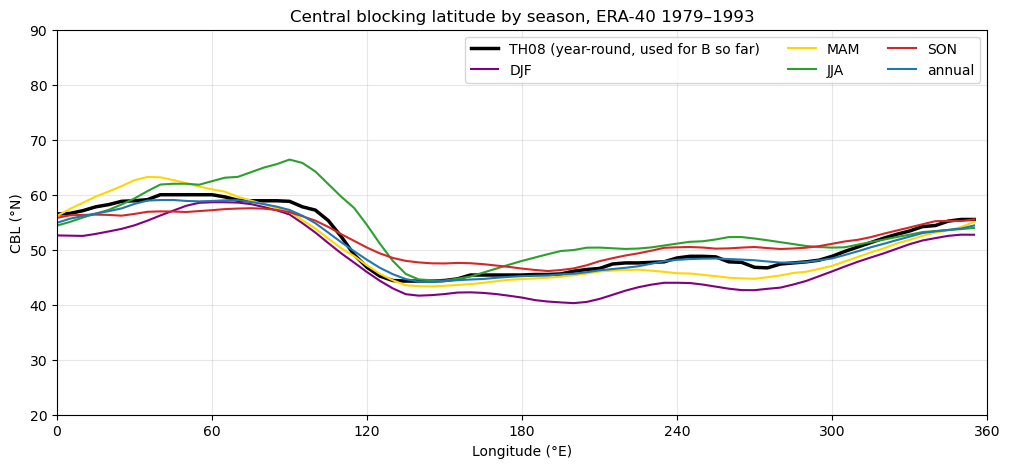

In [8]:
CBL_FILE = "../results/ERA40_CBL_by_season_1979-1993.csv"

if os.path.exists(CBL_FILE):
    cbl_by_season = pd.read_csv(CBL_FILE, index_col="lon")
else:
    lats, lons, mean_eke = mean_synoptic_eke_by_season("../data", range(1979, 1994))
    cbl_by_season = pd.DataFrame({key: smoothed_cbl(lats, lons, mean_eke[key]) for key in mean_eke},
                                 index=pd.Index(TARGET_LONS, name="lon"))
    cbl_by_season.to_csv(CBL_FILE)

colors = {"DJF": "purple", "MAM": "gold", "JJA": "tab:green", "SON": "tab:red", "annual": "tab:blue"}   # as TH08 Fig. 1
plt.figure(figsize=(12, 5))
plt.plot(TARGET_LONS, CBL_TH08, color="black", linewidth=2.5, label="TH08 (year-round, used for B so far)")
for key, color in colors.items():
    plt.plot(TARGET_LONS, cbl_by_season[key], color=color, label=key)
plt.xlim(0, 360)
plt.ylim(20, 90)
plt.xticks(range(0, 361, 60))
plt.xlabel("Longitude (°E)")
plt.ylabel("CBL (°N)")
plt.title("Central blocking latitude by season, ERA-40 1979–1993")
plt.grid(alpha=0.3)
plt.legend(ncol=3)
plt.show()

## B with the seasonal central latitudes

Saved to `results/ERA40_B_index_daily_1957-2002_seasonal-CBL.parquet`; loaded if it exists (delete it to recompute).

In [9]:
B_FILE = "../results/ERA40_B_index_daily_1957-2002_seasonal-CBL.parquet"
SEASON_OF_MONTH = {m: season for season, months in SEASONS.items() for m in months}

if os.path.exists(B_FILE):
    B_seasonal = pd.read_parquet(B_FILE).rename(columns=int)
else:
    W = None
    daily_B = []
    for path in theta_files:
        lats, lons, times, theta = read_theta_month(path)
        if W is None:
            W = {season: build_B_weights(lats, lons, cbl_by_season[season].to_numpy()) for season in SEASONS}
        season = SEASON_OF_MONTH[int(path[-2:])]
        B = pd.DataFrame(compute_B(theta, W[season]), index=pd.DatetimeIndex(times), columns=TARGET_LONS)
        daily_B.append(B.resample("D").mean())
        print(path, "done")
    B_seasonal = pd.concat(daily_B).sort_index()   # rows = days, columns = longitude
    B_seasonal.rename(columns=str).to_parquet(B_FILE)   # parquet needs text column names